# Foundations note — pedagogical figures

Generator for every figure embedded in `docs/notes/sbi_foundations.md`. All figures are **schematic/pedagogical**: they are drawn from the published cross-sections (arithmetic) or from synthetic toy numbers made in this notebook — none of them is an analysis result. Restyle and re-run at will; each figure is one self-contained cell.

Output: `output/foundations-figs/*.png` (gitignored working copies) — published copies live in the public `phd-figures` repo under `sbi-shortcomings/sbi-foundations/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

OUT = Path('../output/foundations-figs'); OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})
C = dict(asimov='#D55E00', toys='#0072B2', band='#0072B2', accent='#009E73', grey='#666666', warn='#CC79A7')

# cross-sections in fb (np.prod of the dataset xs JSON, full precision; == expected yields at 1 fb^-1)
S, I, B = 2*1.83*0.08467131148, 2*1.83*(-0.1656920766), 2*1.83*1.6265120219
def nu(mu, L=1.0):
    mu = np.asarray(mu, dtype=float)
    return L * (mu*S + np.sqrt(mu)*I + B)
mu_star = (I/(2*S))**2
print(f'fold at mu* = {mu_star:.3f};  dnu/dmu at mu=1 = {S + I/2:.4f} fb')

fold at mu* = 0.957;  dnu/dmu at mu=1 = 0.0067 fb


## Figure 1 — the interference rate fold

The total rate $\nu(\mu) = L(\mu\sigma_S + \sqrt{\mu}\,\sigma_I + \sigma_B)$ computed from the published cross-sections. Destructive interference ($\sigma_I < 0$) makes the rate **stationary** at $\mu^* = (\sigma_I/2\sigma_S)^2 \approx 0.957$ — essentially on top of the SM point. Left: the rate barely moves across the whole physical range. Right: its derivative crosses zero at $\mu^*$, so to first order the event *count* carries no information about $\mu$ near the truth, and the map $\mu \to \nu$ is two-to-one around the fold.

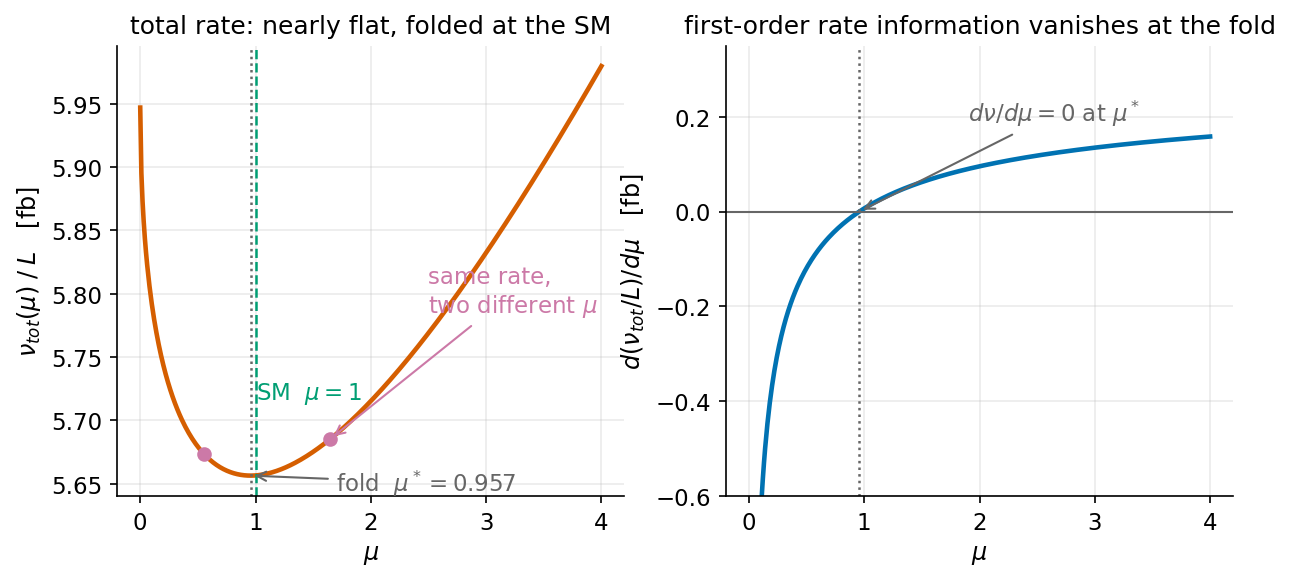

In [2]:
mu = np.linspace(1e-4, 4, 400)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9))

a1.plot(mu, nu(mu), color=C['asimov'], lw=2.2)
a1.axvline(mu_star, color=C['grey'], ls=':', lw=1.2)
a1.axvline(1.0, color=C['accent'], ls='--', lw=1.2)
a1.annotate(f'fold  $\\mu^*={mu_star:.3f}$', (mu_star, nu(mu_star)), xytext=(1.7, nu(mu_star)-0.012),
            arrowprops=dict(arrowstyle='->', color=C['grey']), color=C['grey'])
a1.annotate('SM  $\\mu=1$', (1.0, nu(1.0)+0.06), color=C['accent'])
mu_lo, mu_hi = 0.55, 1.65   # two mu values with the same rate
a1.plot([mu_lo, mu_hi], [nu(mu_lo), nu(mu_hi)], 'o', color=C['warn'], ms=6)
a1.annotate('same rate,\ntwo different $\\mu$', (mu_hi, nu(mu_hi)), xytext=(2.5, nu(mu_hi)+0.10),
            arrowprops=dict(arrowstyle='->', color=C['warn']), color=C['warn'])
a1.set_xlabel('$\\mu$'); a1.set_ylabel('$\\nu_{tot}(\\mu)\\;/\\;L$   [fb]')
a1.set_title('total rate: nearly flat, folded at the SM')

a2.plot(mu, S + I/(2*np.sqrt(mu)), color=C['toys'], lw=2.2)
a2.axhline(0, color=C['grey'], lw=1)
a2.axvline(mu_star, color=C['grey'], ls=':', lw=1.2)
a2.set_ylim(-0.6, 0.35)
a2.annotate('$d\\nu/d\\mu = 0$ at $\\mu^*$', (mu_star, 0.0), xytext=(1.9, 0.19),
            arrowprops=dict(arrowstyle='->', color=C['grey']), color=C['grey'])
a2.set_xlabel('$\\mu$'); a2.set_ylabel('$d(\\nu_{tot}/L)/d\\mu$   [fb]')
a2.set_title('first-order rate information vanishes at the fold')

fig.savefig(OUT/'rate_fold.png'); plt.show()

## Figure 2 — how a toy pseudo-experiment is made

Left: a weighted MC sample is a list of events, each carrying a weight $w_i$ (grey stems). One toy replaces every weight by an integer Poisson draw $w^{toy}_i \sim \mathcal{P}(w_i \cdot L)$ (blue dots): most events contribute 0, some contribute 1, occasionally 2 — the toy *is* the set of events that survived, with their multiplicities. Right: the same recipe seen through a histogram — the Asimov template (weights summed per bin) vs three toys (Poisson draws summed per bin). Rate and shape fluctuate together, which is the point.

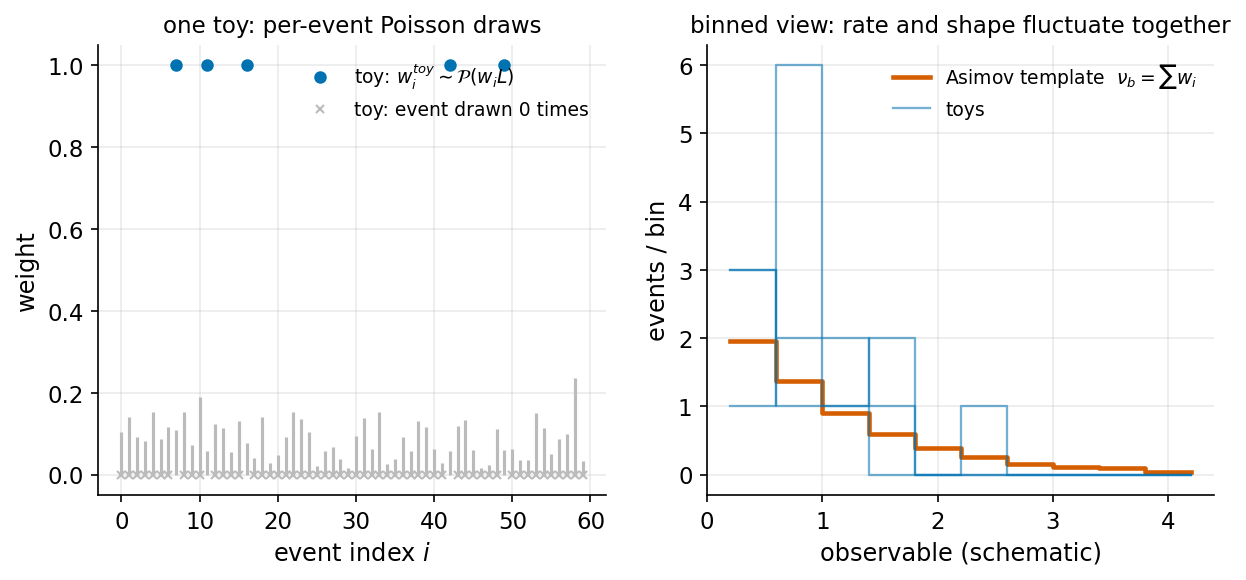

In [3]:
n_ev = 60
w = rng.gamma(2.0, 0.05, n_ev)           # synthetic per-event weights (schematic)
toy = rng.poisson(w)                      # one toy at L=1
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9))

a1.stem(np.arange(n_ev), w, linefmt='#BBBBBB', markerfmt=' ', basefmt=' ')
a1.plot(np.arange(n_ev)[toy>0], toy[toy>0], 'o', color=C['toys'], ms=5, label='toy: $w^{toy}_i \\sim \\mathcal{P}(w_i L)$')
a1.plot(np.arange(n_ev)[toy==0], np.zeros((toy==0).sum()), 'x', color='#BBBBBB', ms=4, label='toy: event drawn 0 times')
a1.set_xlabel('event index $i$'); a1.set_ylabel('weight')
a1.set_title('one toy: per-event Poisson draws', fontsize=11)
a1.legend(loc='upper right', fontsize=9)

x = rng.exponential(1.0, 4000) + 0.2      # synthetic observable (schematic)
wts = np.full(x.size, 6.0/x.size)         # normalised to ~6 expected events
bins = np.linspace(0.2, 4.2, 11); ctr = 0.5*(bins[1:]+bins[:-1])
asimov, _ = np.histogram(x, bins=bins, weights=wts)
a2.step(bins, np.r_[asimov, asimov[-1]], where='post', color=C['asimov'], lw=2.2, label='Asimov template  $\\nu_b=\\sum w_i$')
for k in range(3):
    t, _ = np.histogram(x, bins=bins, weights=rng.poisson(wts*1.0))
    a2.step(bins, np.r_[t, t[-1]], where='post', color=C['toys'], lw=1.1, alpha=0.55, label='toys' if k==0 else None)
a2.set_xlabel('observable (schematic)'); a2.set_ylabel('events / bin')
a2.set_title('binned view: rate and shape fluctuate together', fontsize=11)
a2.legend(loc='upper right', fontsize=9)
fig.savefig(OUT/'toy_mechanics.png'); plt.show()

## Figure 3 — coverage, the operational meaning of an error bar

Sixty synthetic repetitions of the same measurement, each reporting a 68% interval. Left: a **calibrated** procedure — the truth (horizontal line) is inside the interval in ≈ 68% of the experiments. Right: an **overconfident** procedure — same central values, intervals reported 45% too short, so the truth is captured far less often than claimed. Coverage is a property of the *procedure* under repetition, never of a single interval.

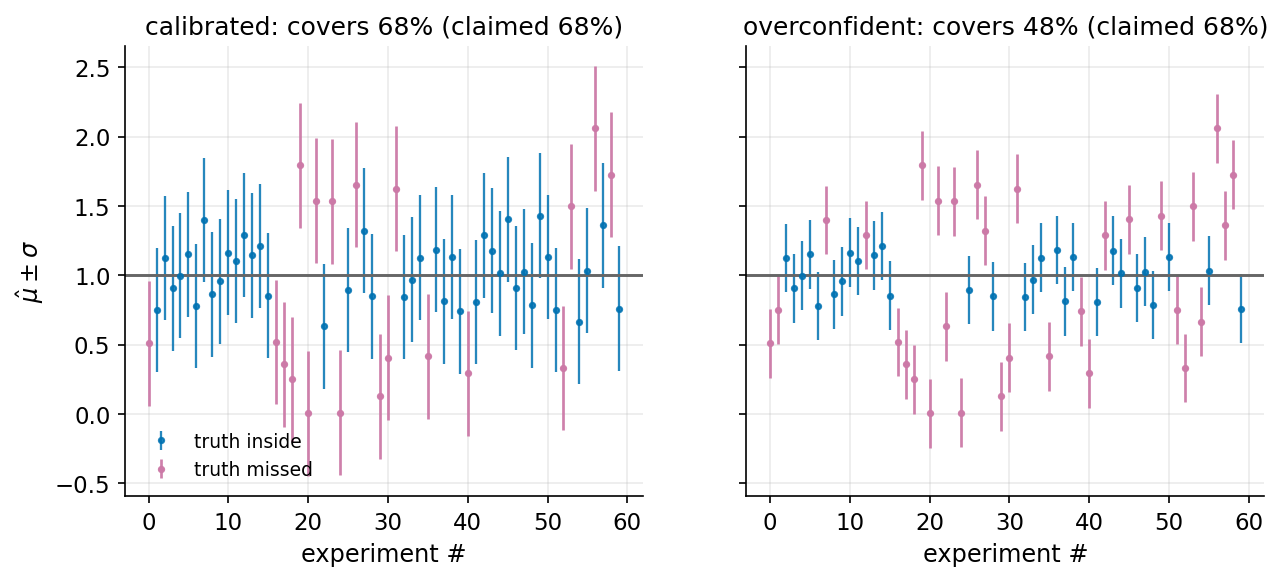

In [4]:
n_exp, truth = 60, 1.0
sig_true = 0.45
muhat = rng.normal(truth, sig_true, n_exp)
fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.9), sharey=True)
for ax, scale, name in [(axes[0], 1.0, 'calibrated'), (axes[1], 0.55, 'overconfident')]:
    half = sig_true*scale
    hit = np.abs(muhat - truth) < half
    ax.errorbar(np.arange(n_exp)[hit], muhat[hit], yerr=half, fmt='o', ms=2.5, color=C['toys'], alpha=0.85, lw=1.1, label='truth inside')
    ax.errorbar(np.arange(n_exp)[~hit], muhat[~hit], yerr=half, fmt='o', ms=2.5, color=C['warn'], alpha=0.95, lw=1.3, label='truth missed')
    ax.axhline(truth, color=C['grey'], lw=1.4)
    ax.set_title(f'{name}: covers {hit.mean():.0%} (claimed 68%)')
    ax.set_xlabel('experiment #')
axes[0].set_ylabel('$\\hat{\\mu} \\pm \\sigma$'); axes[0].legend(loc='lower left', fontsize=9)
fig.savefig(OUT/'coverage.png'); plt.show()

## Figure 4 — what "asymptotic" buys, and what its loss looks like

Left: in the asymptotic regime the scan is a parabola; reading the $\Delta(-2\ln L)=1$ crossings *is* the 68% interval (Wilks + Wald). Right: the exact scan of a plain six-event counting experiment ($\nu(\mu) = 2\mu + 4$, $n = 6$ — no interference, nothing exotic): shallow and asymmetric, and the parabola matched at the minimum (dashed) is a poor description across the range, so the $\Delta = 1$ rule loses its calibration. (Our actual model is *worse* than this: its rate is additionally folded — Figure 1.)

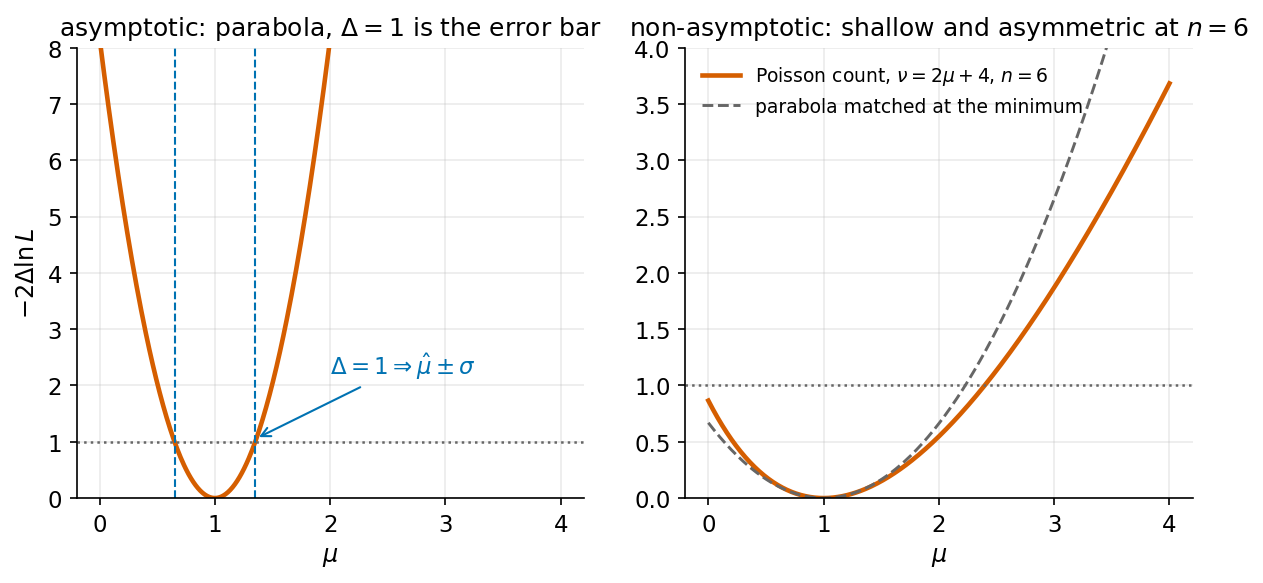

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
mu = np.linspace(0.0, 4, 400)

sig = 0.35
t_par = ((mu-1)/sig)**2
a1.plot(mu, t_par, color=C['asimov'], lw=2.2)
a1.axhline(1, color=C['grey'], ls=':', lw=1.2)
for x_ in (1-sig, 1+sig): a1.axvline(x_, color=C['toys'], ls='--', lw=1)
a1.annotate('$\\Delta = 1 \\Rightarrow \\hat{\\mu}\\pm\\sigma$', (1+sig, 1.05), xytext=(2.0, 2.2),
            arrowprops=dict(arrowstyle='->', color=C['toys']), color=C['toys'])
a1.set_ylim(0, 8); a1.set_xlabel('$\\mu$'); a1.set_ylabel('$-2\\Delta\\ln L$')
a1.set_title('asymptotic: parabola, $\\Delta=1$ is the error bar')

# plain low-count experiment (no fold): nu = mu*s + b, observe the Asimov count
s_, b_ = 2.0, 4.0
nu_mu = mu*s_ + b_
n_obs = 1.0*s_ + b_
t_pois = 2*(nu_mu - n_obs + n_obs*np.log(n_obs/np.clip(nu_mu, 1e-9, None)))
t_pois -= t_pois.min()
a2.plot(mu, t_pois, color=C['asimov'], lw=2.2, label='Poisson count, $\\nu = 2\\mu + 4$, $n = 6$')
imin = np.argmin(t_pois)
curv = np.gradient(np.gradient(t_pois, mu), mu)[imin]
a2.plot(mu, 0.5*curv*(mu-mu[imin])**2, color=C['grey'], ls='--', lw=1.4, label='parabola matched at the minimum')
a2.axhline(1, color=C['grey'], ls=':', lw=1.2)
a2.set_ylim(0, 4); a2.set_xlabel('$\\mu$')
a2.set_title('non-asymptotic: shallow and asymmetric at $n = 6$')
a2.legend(loc='upper left', fontsize=9)
fig.savefig(OUT/'wilks_wald.png'); plt.show()

## Figure 5 — the founding observation (schematic cartoon)

A **redrawn cartoon** of the behaviour that started the project — deliberately schematic, no measured curves. Left: histogram analysis — the median of the toy scans (solid) tracks the Asimov scan (dashed) at every luminosity. Right: NSBI at low luminosity — the toy median is systematically **steeper** than the Asimov: each pseudo-experiment claims more sensitivity than the expectation-level fit predicts. That gap, and its disappearance at high luminosity, is the phenomenon under study.

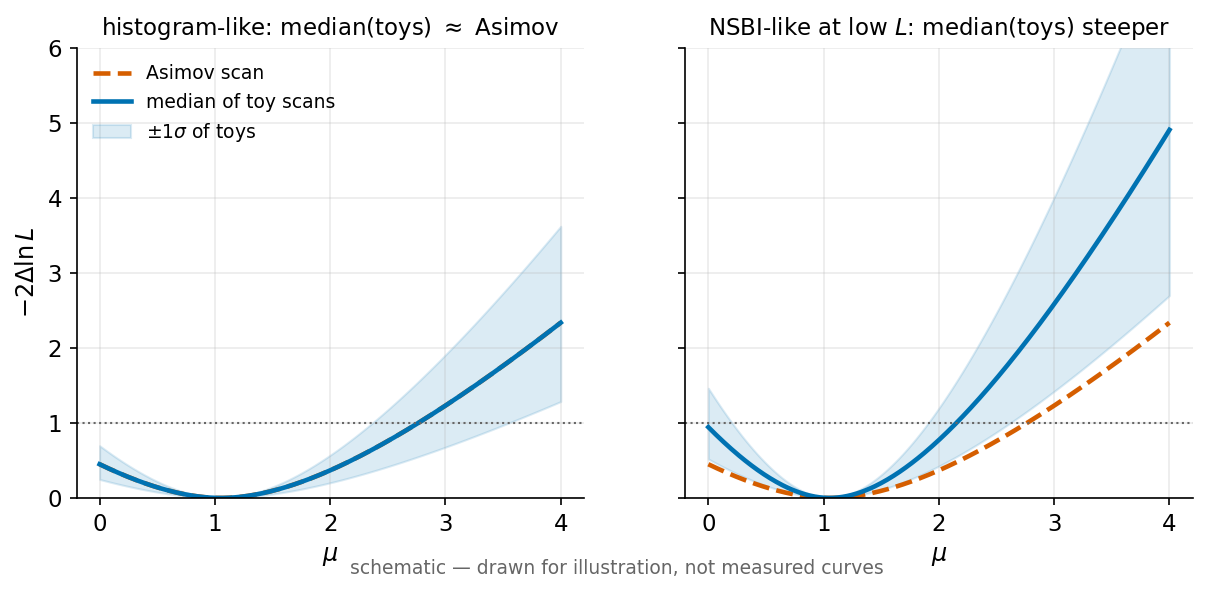

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
mu = np.linspace(0, 4, 300)
base = 0.55*(mu-1.05)**2/(1+0.35*np.abs(mu-1))

for a, extra, ttl in [(a1, 1.0, 'histogram-like: median(toys) $\\approx$ Asimov'),
                      (a2, 2.1, 'NSBI-like at low $L$: median(toys) steeper')]:
    a.plot(mu, base, ls='--', lw=2.2, color=C['asimov'], label='Asimov scan')
    med = base*extra
    a.plot(mu, med, lw=2.2, color=C['toys'], label='median of toy scans')
    a.fill_between(mu, med*0.55, med*1.55, color=C['band'], alpha=0.14, label='$\\pm1\\sigma$ of toys')
    a.axhline(1, color=C['grey'], ls=':', lw=1)
    a.set_xlabel('$\\mu$'); a.set_title(ttl, fontsize=11)
a1.set_ylabel('$-2\\Delta\\ln L$'); a1.set_ylim(0, 6); a1.legend(loc='upper left', fontsize=9)
fig.text(0.5, -0.02, 'schematic — drawn for illustration, not measured curves', ha='center', fontsize=9, color=C['grey'])
fig.savefig(OUT/'asimov_vs_toys_schematic.png'); plt.show()

## Figure 6 — the CARL/NSBI pipeline

From two labelled samples to a full μ-dependent likelihood: a classifier per density ratio, the likelihood-ratio trick, the mixture model, and the analytic rate term joining only at the very end.

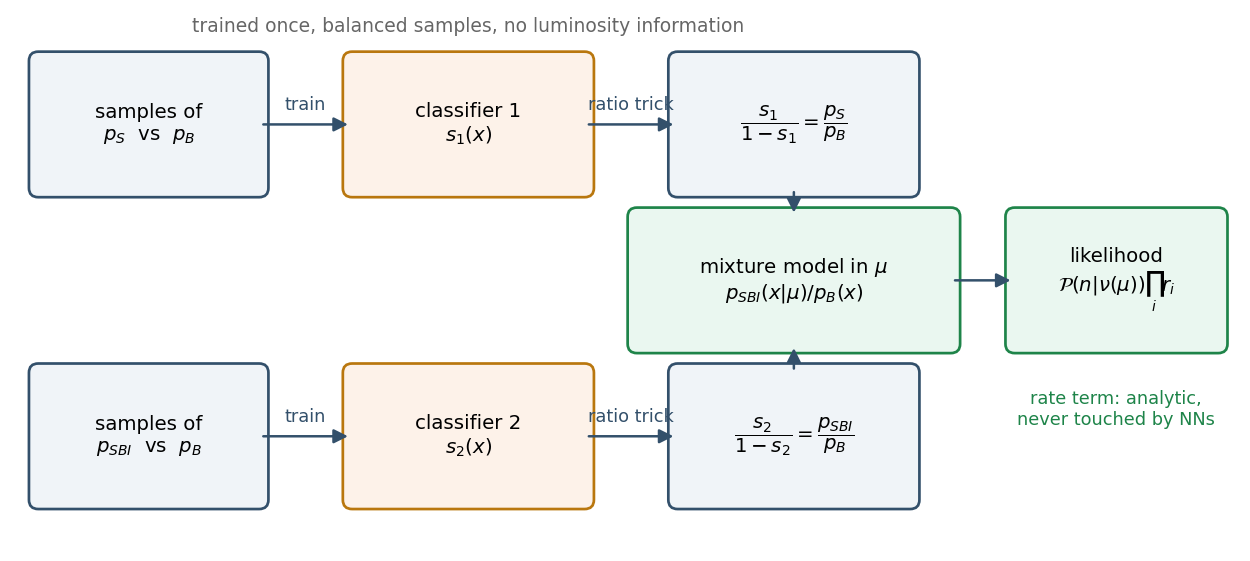

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 4.6)); ax.axis('off'); ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.6)

def box(x, y, w, h, text, fc='#F0F4F8', ec='#33506B', fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08', fc=fc, ec=ec, lw=1.3))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=fs)
def arrow(x1, y1, x2, y2, text=None, fs=8.5):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=14, color='#33506B', lw=1.2))
    if text: ax.text((x1+x2)/2, (y1+y2)/2+0.13, text, ha='center', fontsize=fs, color='#33506B')

box(0.2, 3.1, 1.9, 1.1, 'samples of\n$p_S$  vs  $p_B$')
box(0.2, 0.4, 1.9, 1.1, 'samples of\n$p_{SBI}$  vs  $p_B$')
box(2.9, 3.1, 2.0, 1.1, 'classifier 1\n$s_1(x)$', fc='#FDF2E9', ec='#B9770E')
box(2.9, 0.4, 2.0, 1.1, 'classifier 2\n$s_2(x)$', fc='#FDF2E9', ec='#B9770E')
box(5.7, 3.1, 2.0, 1.1, '$\\dfrac{s_1}{1-s_1} = \\dfrac{p_S}{p_B}$')
box(5.7, 0.4, 2.0, 1.1, '$\\dfrac{s_2}{1-s_2} = \\dfrac{p_{SBI}}{p_B}$')
box(5.35, 1.75, 2.7, 1.1, 'mixture model in $\\mu$\n$p_{SBI}(x|\\mu)/p_B(x)$', fc='#EAF7F0', ec='#1E8449')
box(8.6, 1.75, 1.75, 1.1, 'likelihood\n$\\mathcal{P}(n|\\nu(\\mu))\\prod_i r_i$', fc='#EAF7F0', ec='#1E8449')
arrow(2.1, 3.65, 2.9, 3.65, 'train'); arrow(2.1, 0.95, 2.9, 0.95, 'train')
arrow(4.9, 3.65, 5.7, 3.65, 'ratio trick'); arrow(4.9, 0.95, 5.7, 0.95, 'ratio trick')
arrow(6.7, 3.1, 6.7, 2.85); arrow(6.7, 1.5, 6.7, 1.75)
arrow(8.05, 2.3, 8.6, 2.3)
ax.text(9.47, 1.05, 'rate term: analytic,\nnever touched by NNs', ha='center', fontsize=8.5, color='#1E8449')
ax.text(3.9, 4.45, 'trained once, balanced samples, no luminosity information', ha='center', fontsize=9, color='#666666')
fig.savefig(OUT/'carl_pipeline.png'); plt.show()

## Figure 7 — Deep Sets: a network whose input is a whole dataset

Every event is embedded by the same network φ; the embeddings are **summed** — so the pooled vector moves when events are added, carrying the sample size — and ρ maps the pooled vector to the output. Mean pooling (grey) would divide the sum by N and become blind to how much data there is: the exact blindness toy-ensemble training is meant to cure.

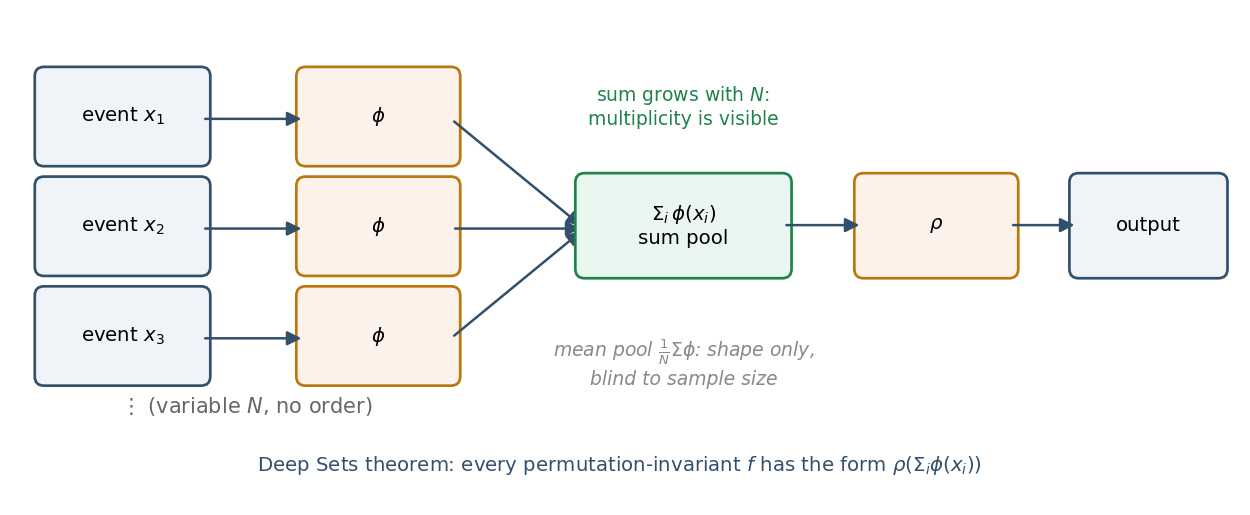

In [8]:
fig, ax = plt.subplots(figsize=(10.5, 4.2)); ax.axis('off'); ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.2)

for k, yy in enumerate([3.3, 2.35, 1.4]):
    box(0.25, yy-0.33, 1.35, 0.7, f'event $x_{{{k+1}}}$')
    box(2.5, yy-0.33, 1.25, 0.7, '$\\phi$', fc='#FDF2E9', ec='#B9770E')
    arrow(1.6, yy, 2.5, yy)
    arrow(3.75, yy, 4.9, 2.35 if yy!=2.35 else 2.35)
ax.text(0.9, 0.75, '$\\vdots$ (variable $N$, no order)', fontsize=10, color='#666666')
box(4.9, 2.0, 1.7, 0.75, '$\\Sigma_i\\, \\phi(x_i)$\nsum pool', fc='#EAF7F0', ec='#1E8449')
box(7.3, 2.0, 1.25, 0.75, '$\\rho$', fc='#FDF2E9', ec='#B9770E')
box(9.15, 2.0, 1.2, 0.75, 'output')
arrow(6.6, 2.38, 7.3, 2.38); arrow(8.55, 2.38, 9.15, 2.38)
ax.text(5.75, 3.25, 'sum grows with $N$:\nmultiplicity is visible', ha='center', fontsize=9, color='#1E8449')
ax.text(5.75, 1.0, 'mean pool $\\frac{1}{N}\\Sigma\\phi$: shape only,\nblind to sample size', ha='center', fontsize=9, color='#888888', style='italic')
ax.text(5.2, 0.25, 'Deep Sets theorem: every permutation-invariant $f$ has the form $\\rho(\\Sigma_i \\phi(x_i))$', ha='center', fontsize=9.5, color='#33506B')
fig.savefig(OUT/'deepsets.png'); plt.show()

## Figure 8 — the effective sample size of the score

Two synthetic experiments with the *same* number of events (N = 100) but different per-event score contributions $u_i$. Left: contributions of similar size → $N_{eff} = (\Sigma u)^2/\Sigma u^2 \approx N$; the CLT has 100 terms to work with. Right: a heavy-tailed set where a handful of events carry the sum → $N_{eff}$ collapses by an order of magnitude; formally 100 events, statistically a few-dozen-event experiment (and the tail can push it to single digits). This — not "events per bin" — is the quantity that decides whether a per-event likelihood is in the asymptotic regime.

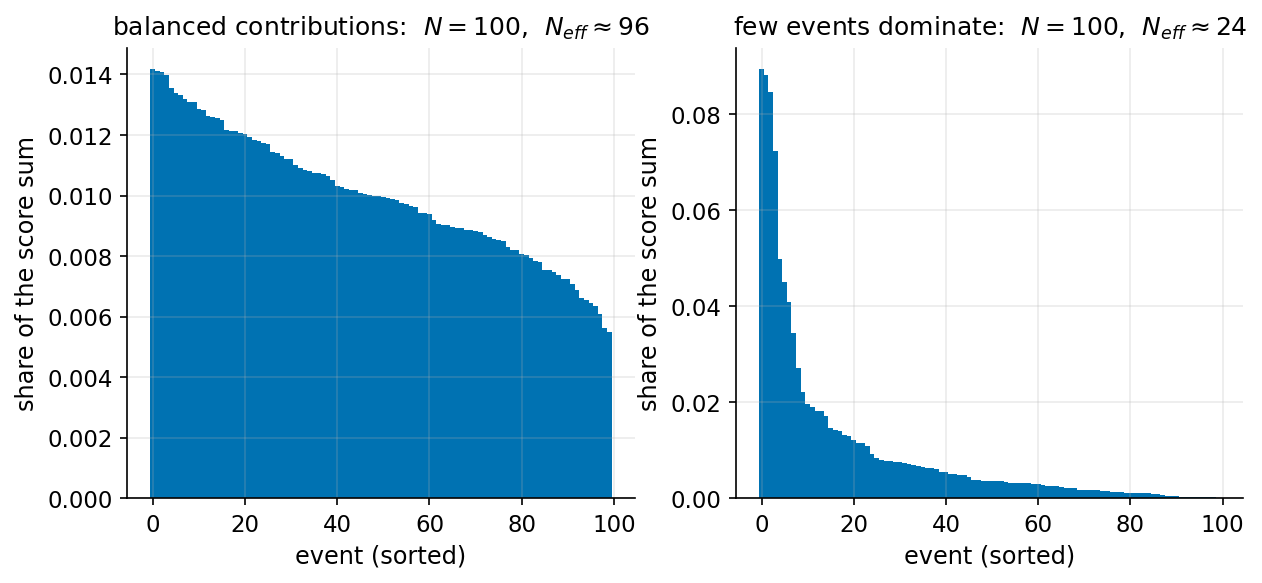

figures written to /project/atlas/Users/mfernand/SBI_shortcomings/output/foundations-figs


In [9]:
N = 100
u_flat = rng.gamma(20, 1/20, N)
u_heavy = rng.pareto(0.85, N) + 0.02
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=False)
for ax, u, ttl in [(axes[0], u_flat, 'balanced contributions'), (axes[1], u_heavy, 'few events dominate')]:
    u = np.sort(u)[::-1]
    neff = u.sum()**2/np.square(u).sum()
    ax.bar(np.arange(N), u/u.sum(), color=C['toys'], width=1.0)
    ax.set_title(f'{ttl}:  $N=100$,  $N_{{eff}} \\approx {neff:.0f}$')
    ax.set_xlabel('event (sorted)'); ax.set_ylabel('share of the score sum')
fig.savefig(OUT/'neff_score.png'); plt.show()
print('figures written to', OUT.resolve())

## Figure 9 — Feldman–Cousins: the ordering rule, and the two pathologies it cures

**Left.** The Neyman construction fixes the *size* of each acceptance region but not *which* outcomes go into it. Choosing after the fact — an upper limit if the result is insignificant, a central interval if it is not ("flip-flopping") — makes the ordering depend on the data, and it **undercovers**: the nominal 90% procedure covers only 85% over true μ ≈ 1.3–4.6. The Feldman–Cousins likelihood-ratio ordering fixes the rule *before* the data and holds coverage at nominal everywhere.

**Right.** The FC belt for a Poisson with known background b = 3. The interval for an observed n is the vertical slice through the belt. The construction passes from an upper limit (n ≲ b) to a two-sided interval (n ≳ b) with no discontinuity, and never returns an empty set. Cross-checked against Feldman & Cousins (1998), Table IV.

flip-flop coverage dips to 0.850 at mu = 1.80 (nominal 0.90);  FC minimum 0.900
  n =  0:  FC 90% interval = [0.00, 0.95]
  n =  1:  FC 90% interval = [0.00, 1.87]
  n =  2:  FC 90% interval = [0.00, 3.03]
  n =  4:  FC 90% interval = [0.00, 5.59]
  n =  6:  FC 90% interval = [0.16, 8.46]
  n = 10:  FC 90% interval = [2.64, 12.00]
cross-check vs Feldman & Cousins (1998) Table IV, n = 0:  b=0 -> 2.44,  b=1 -> 1.61,  b=2 -> 1.08


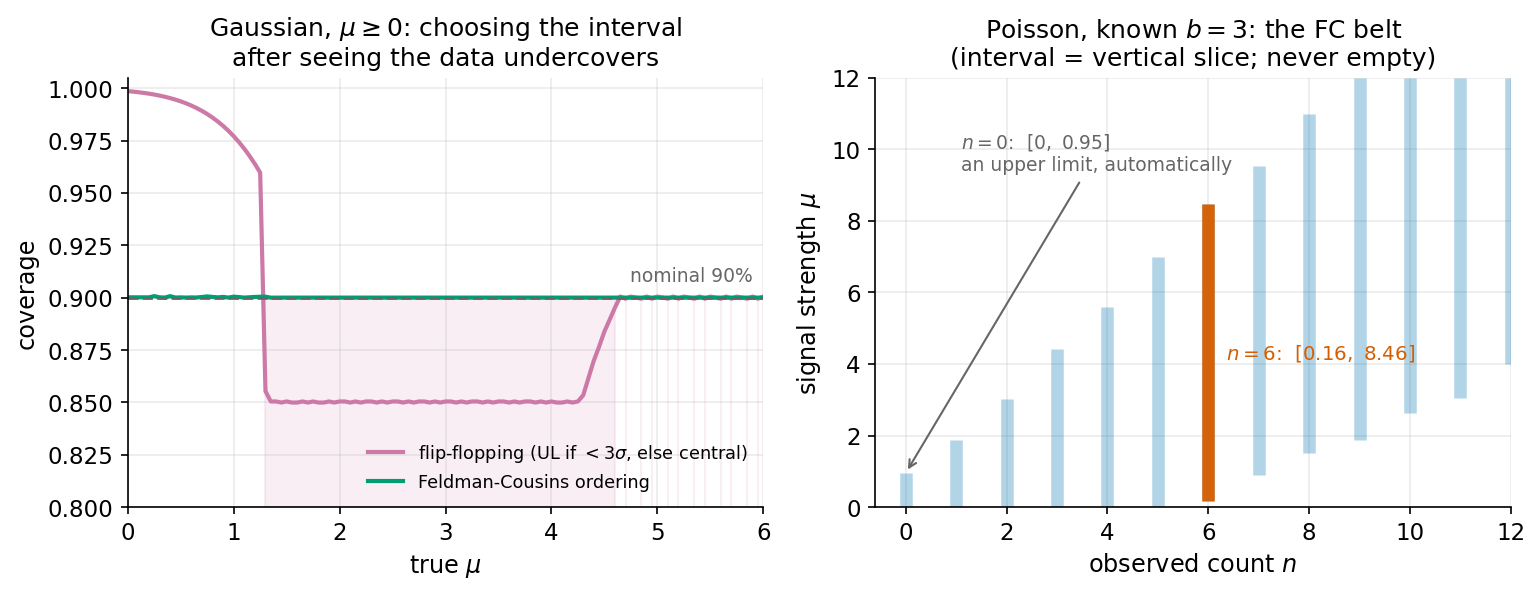

In [10]:
# Feldman-Cousins: the ordering rule, and the two pathologies it cures.
CL = 0.90

# --- (a) Gaussian, mu >= 0: flip-flopping undercovers; the FC ordering does not
xg = np.linspace(-6, 12, 3601); dxg = xg[1] - xg[0]
def gauss(x, m): return np.exp(-0.5*(x - m)**2)/np.sqrt(2*np.pi)

def fc_accept_gauss(mu):
    """FC acceptance region in x at this mu: rank outcomes by R = P(x|mu)/P(x|mu_best), mu_best = max(x, 0)."""
    p = gauss(xg, mu)
    R = p / gauss(xg, np.maximum(xg, 0.0))
    o = np.argsort(-R)
    k = np.searchsorted(np.cumsum(p[o])*dxg, CL) + 1
    keep = np.zeros_like(xg, bool); keep[o[:k]] = True
    return keep

mus = np.linspace(0, 6, 121)
z_ul, z_cen = 1.282, 1.645          # 90% one-sided / two-sided normal quantiles
cov_fc, cov_ff = [], []
for mu in mus:
    p = gauss(xg, mu)
    cov_fc.append((p*fc_accept_gauss(mu)).sum()*dxg)
    # flip-flop: quote an upper limit below 3 sigma, a central interval above it
    lo = np.where(xg < 3.0, 0.0, xg - z_cen)
    hi = np.where(xg < 3.0, np.maximum(xg, 0.0) + z_ul, xg + z_cen)
    cov_ff.append((p*((lo <= mu) & (mu <= hi))).sum()*dxg)

# --- (b) Poisson with known background: the FC belt
b, mu_max, n_show, nmax = 3.0, 12.0, 12, 60      # nmax must hold the Poisson mass out to lam = mu_max + b
ns = np.arange(nmax + 1)
logfact = np.concatenate(([0.0], np.cumsum(np.log(np.arange(1, nmax + 1)))))
def pois(ns, lam): return np.exp(ns*np.log(np.maximum(lam, 1e-12)) - lam - logfact[ns])

p_best = pois(ns, np.maximum(ns - b, 0.0) + b)   # best-fit mu, restricted to the physical region
mu_grid = np.linspace(0, mu_max, 1201)
belt = np.zeros((mu_grid.size, nmax + 1), bool)
for j, mu in enumerate(mu_grid):
    p = pois(ns, mu + b)
    o = np.argsort(-(p/p_best))                  # rank outcomes by the likelihood ratio
    k = np.searchsorted(np.cumsum(p[o]), CL) + 1
    belt[j, o[:k]] = True

def fc_interval(n):
    m = mu_grid[belt[:, n]]
    return (m.min(), m.max()) if m.size else (np.nan, np.nan)

fig, (aA, aB) = plt.subplots(1, 2, figsize=(10.4, 4.1))

aA.plot(mus, cov_ff, color=C['warn'], lw=2.0, label='flip-flopping (UL if $<3\\sigma$, else central)')
aA.plot(mus, cov_fc, color=C['accent'], lw=2.0, label='Feldman-Cousins ordering')
aA.axhline(CL, color=C['grey'], lw=1.3, ls='--')
aA.text(5.9, CL + 0.006, 'nominal 90%', ha='right', va='bottom', fontsize=9, color=C['grey'])
aA.fill_between(mus, 0.80, CL, where=np.array(cov_ff) < CL, color=C['warn'], alpha=0.12)
aA.set_xlim(0, 6); aA.set_ylim(0.80, 1.005)
aA.set_xlabel('true $\\mu$'); aA.set_ylabel('coverage')
aA.set_title('Gaussian, $\\mu \\geq 0$: choosing the interval\nafter seeing the data undercovers')
aA.legend(loc='lower right', fontsize=8.5)

for n in ns[:n_show + 1]:
    m = mu_grid[belt[:, n]]
    if m.size:
        aB.plot([n, n], [m.min(), m.max()], color=C['toys'], lw=6, alpha=0.30, solid_capstyle='butt')
n_obs = 6; lo6, hi6 = fc_interval(n_obs)
aB.plot([n_obs, n_obs], [lo6, hi6], color=C['asimov'], lw=6, alpha=0.95, solid_capstyle='butt', zorder=3)
aB.annotate(f'$n={n_obs}$:  $[{lo6:.2f},\\ {hi6:.2f}]$', xy=(n_obs + 0.35, (lo6 + hi6)/2),
            fontsize=9.5, color=C['asimov'], va='center')
hi0 = fc_interval(0)[1]
aB.annotate(f'$n=0$:  $[0,\\ {hi0:.2f}]$\nan upper limit, automatically', xy=(0, hi0), xytext=(1.1, 9.4),
            fontsize=9, color=C['grey'], arrowprops=dict(arrowstyle='->', color=C['grey'], lw=1.0))
aB.set_xlim(-0.6, n_show); aB.set_ylim(0, mu_max)
aB.set_xlabel('observed count $n$'); aB.set_ylabel('signal strength $\\mu$')
aB.set_title(f'Poisson, known $b={b:.0f}$: the FC belt\n(interval = vertical slice; never empty)')

fig.tight_layout(); fig.savefig(OUT/'feldman_cousins.png'); plt.show()

print(f'flip-flop coverage dips to {min(cov_ff):.3f} at mu = {mus[int(np.argmin(cov_ff))]:.2f} (nominal {CL:.2f});  FC minimum {min(cov_fc):.3f}')
for n in [0, 1, 2, 4, 6, 10]:
    l, h = fc_interval(n)
    print(f'  n = {n:>2}:  FC 90% interval = [{l:.2f}, {h:.2f}]')
print('cross-check vs Feldman & Cousins (1998) Table IV, n = 0:  b=0 -> 2.44,  b=1 -> 1.61,  b=2 -> 1.08')